# Job-Recruitment Phishing URL Detection with Random Forest

Lexical-feature classifier on a pre-split dataset (`train_features.csv`, `test_features.csv`).

**Pipeline:** data audit → cleaning → host-grouped cross-validation on the training set → (optional) hyperparameter search → single evaluation on the held-out test set → feature importance (impurity-based and permutation-based).

Two design choices differ from a minimal tutorial and matter for a publishable result:

1. **Group-aware validation.** Legitimate URLs in this corpus come from a small set of job portals, so rows from the same host are not independent. Cross-validation and tuning use `StratifiedGroupKFold` with the host as the group, so a fold never trains and validates on the same site.
2. **Two importance measures.** Mean Decrease in Impurity (MDI) is biased toward continuous, high-cardinality features [1]. Permutation importance on the test set is reported alongside it as the less biased reference.

The test set is used exactly once, after all modelling decisions are fixed.

## 1. Setup

In [1]:
import hashlib
import io
import urllib.request
import warnings
from pathlib import Path
from urllib.parse import urlsplit

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, classification_report,
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42                 # single seed for every stochastic component
N_SPLITS = 5              # folds for grouped cross-validation
RUN_TUNING = False        # set True to run the randomized hyperparameter search (section 7)

# Data source. Local files take priority (e.g. uploaded to the Colab session);
# otherwise the files are downloaded from DATA_BASE_URL.
DATA_BASE_URL = "https://raw.githubusercontent.com/fizzz96/phishing-url-rf/main/data"
DATA_FILES = {
    # filename: expected SHA-256 (guarantees every run uses the identical dataset)
    "train_features.csv": "b62d19c9d1f07d504cbfac679a06bd07c7b212926e24947cfcb9eb4c10706c2a",
    "test_features.csv":  "9cf35014953f51dac1b249cbaf067f00b40b259480af488a251f8753c214fb4e",
}
TARGET = "ClassLabel"     # 1 = phishing, 0 = legitimate
CSV_SEP = ","             # field delimiter of both CSV files
ID_COL = "url"

FEATURES = [
    "urllength", "hasipaddress", "dotcount", "httpsflag", "urlentropy",
    "subdomaincount", "queryparamcount", "tldlength", "pathlength", "hash",
    "hyphenindomain", "tldpopularity", "suspiciousfileextension",
    "domainnamelength", "percentagenumericchars", "count_dashes",
    "count_underscores", "count_slashes", "count_ques", "count_non_alphanumeric",
    "count_equal", "count_ampersand", "count_digits", "count_letters",
]

np.random.seed(SEED)
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight"})

## 2. Load data

Files are read from the working directory if present, otherwise downloaded from `DATA_BASE_URL`, so the notebook runs for anyone without manual uploads. A SHA-256 check confirms every run uses byte-identical data. Both files are comma-delimited (`CSV_SEP`). The schema check fails early if a column is missing or renamed, instead of failing later with an obscure shape error.

In [2]:
def load_split(filename: str) -> pd.DataFrame:
    # Read local copy if present, else download; verify SHA-256 either way.
    local = Path(filename)
    if local.exists():
        raw, source = local.read_bytes(), str(local)
    else:
        if "<github-username>" in DATA_BASE_URL:
            raise FileNotFoundError(
                f"{filename} is not in the working directory and DATA_BASE_URL is still a placeholder. "
                "Upload the CSV files to this session or set DATA_BASE_URL in section 1."
            )
        source = f"{DATA_BASE_URL.rstrip('/')}/{filename}"
        with urllib.request.urlopen(source, timeout=60) as resp:
            raw = resp.read()

    digest = hashlib.sha256(raw).hexdigest()
    expected = DATA_FILES[filename]
    if digest != expected:
        raise ValueError(f"{filename}: SHA-256 mismatch (got {digest[:12]}..., expected {expected[:12]}...). "
                         "The file differs from the version used in the paper.")
    print(f"Loaded {filename} from {source} (SHA-256 verified)")
    return pd.read_csv(io.BytesIO(raw), sep=CSV_SEP)

train_df = load_split("train_features.csv")
test_df = load_split("test_features.csv")

expected = [ID_COL, TARGET] + FEATURES
for name, df in [("train", train_df), ("test", test_df)]:
    missing_cols = set(expected) - set(df.columns)
    assert not missing_cols, f"{name}: missing columns {missing_cols}"

print(f"Train: {train_df.shape[0]:,} rows x {train_df.shape[1]} cols")
print(f"Test : {test_df.shape[0]:,} rows x {test_df.shape[1]} cols")
train_df.head()

Loaded train_features.csv from train_features.csv (SHA-256 verified)
Loaded test_features.csv from test_features.csv (SHA-256 verified)
Train: 6,298 rows x 26 cols
Test : 1,575 rows x 26 cols


,url,ClassLabel,urllength,hasipaddress,dotcount,httpsflag,urlentropy,subdomaincount,queryparamcount,tldlength,...,percentagenumericchars,count_dashes,count_underscores,count_slashes,count_ques,count_non_alphanumeric,count_equal,count_ampersand,count_digits,count_letters
0,https://www.simplyhired.com/?rfr=ema&gch=90892...,0,91,0,3,1,4.872166,1,5,3,...,0.186813,0,1,3,1,18,5,4,17,56
1,http://i-seas.co.in/css/seas/linkedin/linkedin...,1,81,0,3,0,4.217781,0,0,5,...,0.074074,1,0,8,0,19,0,0,6,56
2,https://www.jobstreet.co.id/%40realty-jobs,0,42,0,3,1,4.293771,1,0,5,...,0.047619,1,0,3,0,9,0,0,2,31
3,https://www.metacareers.com/profile/job_detail...,0,65,0,2,1,4.704695,1,0,3,...,0.246154,0,1,6,0,10,0,0,16,39
4,https://euqzswah.garmentsdrycleaners.in/?swahj...,1,599,0,5,1,5.256425,1,2,2,...,0.198664,14,0,6,1,41,3,1,119,439


## 3. Data audit

Checks performed before any modelling:

- missing values per column;
- class balance in each split;
- zero-variance features (carry no information and should be removed);
- strongly correlated feature pairs, which split importance between them;
- duplicate feature vectors and train–test overlap, at both URL level and host level. Host overlap is the relevant leakage measure for URL classifiers: a model can score well by memorising site-specific patterns rather than learning phishing structure.

In [3]:
def extract_host(url: str) -> str:
    # Hostname without a leading "www."; handles URLs that lack a scheme.
    u = url if "://" in url else "http://" + url
    host = (urlsplit(u).hostname or "").lower()
    return host[4:] if host.startswith("www.") else host

for df in (train_df, test_df):
    df["host"] = df[ID_COL].astype(str).map(extract_host)

# Missing values
na = pd.DataFrame({"train": train_df[FEATURES + [TARGET]].isna().sum(),
                   "test": test_df[FEATURES + [TARGET]].isna().sum()})
print("Missing values (columns with any):")
print(na[na.sum(axis=1) > 0] if na.values.any() else "  none")

# Class balance
balance = pd.DataFrame({
    "train_n": train_df[TARGET].value_counts(),
    "train_%": train_df[TARGET].value_counts(normalize=True).mul(100).round(1),
    "test_n": test_df[TARGET].value_counts(),
    "test_%": test_df[TARGET].value_counts(normalize=True).mul(100).round(1),
}).rename(index={0: "legitimate", 1: "phishing"})
print("\nClass balance:")
print(balance)

# Zero-variance features (decided on train only)
constant = [c for c in FEATURES if train_df[c].nunique(dropna=False) <= 1]
print("\nZero-variance features in train:", constant or "none")

# Duplicates and overlap
print("\nDuplicate URLs  - train:", train_df[ID_COL].duplicated().sum(),
      "| test:", test_df[ID_COL].duplicated().sum())
print("URLs in both splits:", len(set(train_df[ID_COL]) & set(test_df[ID_COL])))
print("Duplicate feature vectors in train:", train_df[FEATURES].duplicated().sum())

train_hosts = set(train_df["host"])
overlap = (test_df.assign(seen=test_df["host"].isin(train_hosts))
           .groupby(TARGET)["seen"].mean().mul(100).round(1)
           .rename(index={0: "legitimate", 1: "phishing"}))
print("\nUnique hosts in train by class:")
print(train_df.groupby(TARGET)["host"].nunique().rename(index={0: "legitimate", 1: "phishing"}))
print("\n% of test rows whose host also appears in train:")
print(overlap)

# Redundant feature pairs (|Spearman rho| >= 0.9), informative for importance interpretation
rho = train_df[[c for c in FEATURES if c not in constant]].corr(method="spearman").abs()
pairs = (rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
         .loc[lambda s: s >= 0.9].sort_values(ascending=False).round(3))
print("\nFeature pairs with |Spearman rho| >= 0.9:")
print(pairs.to_string() if len(pairs) else "  none")

Missing values (columns with any):
  none

Class balance:
            train_n  train_%  test_n  test_%
ClassLabel                                  
phishing       3600     57.2     900    57.1
legitimate     2698     42.8     675    42.9

Zero-variance features in train: ['hasipaddress', 'hash', 'suspiciousfileextension']

Duplicate URLs  - train: 0 | test: 0
URLs in both splits: 0
Duplicate feature vectors in train: 278

Unique hosts in train by class:
ClassLabel
legitimate      63
phishing      2181
Name: host, dtype: int64

% of test rows whose host also appears in train:
ClassLabel
legitimate    99.1
phishing      54.4
Name: seen, dtype: float64

Feature pairs with |Spearman rho| >= 0.9:
queryparamcount         count_ques       0.980
percentagenumericchars  count_digits     0.966
urllength               count_letters    0.962
queryparamcount         count_equal      0.941
count_ques              count_equal      0.920


## 4. Cleaning

- **Missing values:** median imputation, with medians computed on the training set only and applied to both splits (no test information enters preprocessing). The code is a no-op when nothing is missing.
- **Zero-variance features:** dropped.
- **`url`:** dropped from the feature matrix. Its derived `host` is kept *outside* the feature matrix, solely as the grouping variable for cross-validation.

No scaling is applied: tree splits are invariant to monotonic transformations of a feature.

In [4]:
features = [c for c in FEATURES if c not in constant]

train_medians = train_df[features].median()
train_df[features] = train_df[features].fillna(train_medians)
test_df[features] = test_df[features].fillna(train_medians)

train_model = train_df.drop(columns=[ID_COL])
test_model = test_df.drop(columns=[ID_COL])

print(f"Dropped zero-variance: {constant or 'none'}")
print(f"Features used ({len(features)}): {features}")

Dropped zero-variance: ['hasipaddress', 'hash', 'suspiciousfileextension']
Features used (21): ['urllength', 'dotcount', 'httpsflag', 'urlentropy', 'subdomaincount', 'queryparamcount', 'tldlength', 'pathlength', 'hyphenindomain', 'tldpopularity', 'domainnamelength', 'percentagenumericchars', 'count_dashes', 'count_underscores', 'count_slashes', 'count_ques', 'count_non_alphanumeric', 'count_equal', 'count_ampersand', 'count_digits', 'count_letters']


## 5. Feature matrix and target

In [5]:
X_train, y_train = train_model[features], train_model[TARGET].astype(int)
X_test, y_test = test_model[features], test_model[TARGET].astype(int)
groups_train = train_model["host"]          # used only to build CV folds

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (6298, 21) | X_test: (1575, 21)


## 6. Model and grouped cross-validation

Random Forest configuration:

- `n_estimators=500` — enough trees for stable votes and importance estimates; RF does not overfit as trees are added, it only costs compute.
- `max_features="sqrt"` — the standard decorrelation setting for classification [2].
- `class_weight=None` — the class ratio is roughly 57:43, which is mild; reweighting is left to the tuning step.
- `random_state=SEED`, `n_jobs=-1`.

The cross-validation estimate below is the number to compare against the test result. A large gap would indicate that the fixed train/test split is easier or harder than expected.

In [6]:
rf = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    class_weight=None,
    random_state=SEED,
    n_jobs=-1,
)

cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
scoring = {
    "accuracy": "accuracy", "precision": "precision", "recall": "recall",
    "f1": "f1", "roc_auc": "roc_auc", "mcc": "matthews_corrcoef",
}
cv_res = cross_validate(rf, X_train, y_train, groups=groups_train,
                        cv=cv, scoring=scoring, n_jobs=-1)

cv_summary = pd.DataFrame({
    m: [cv_res[f"test_{m}"].mean(), cv_res[f"test_{m}"].std(ddof=1)] for m in scoring
}, index=["mean", "sd"]).T.round(4)
print(f"{N_SPLITS}-fold StratifiedGroupKFold (groups = host) on training set:")
print(cv_summary)

5-fold StratifiedGroupKFold (groups = host) on training set:
             mean      sd
accuracy   0.8784  0.0431
precision  0.8436  0.0531
recall     0.9706  0.0101
f1         0.9020  0.0322
roc_auc    0.9775  0.0095
mcc        0.7587  0.0830


## 7. Hyperparameter tuning (optional)

Randomized search over the parameters that most affect RF bias–variance. It uses the same grouped folds as section 6, so the selected configuration is not rewarded for memorising hosts. Optimised for F1 on the phishing class.

Set `RUN_TUNING = True` in section 1 to run it (≈40 configurations × 5 folds). Report the CV score of the best configuration, not the test score, as the basis for selection.

In [7]:
if RUN_TUNING:
    param_dist = {
        "n_estimators": [300, 500, 800],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", "log2", 0.5],
        "class_weight": [None, "balanced"],
    }
    search = RandomizedSearchCV(
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        param_distributions=param_dist,
        n_iter=40,
        scoring="f1",
        cv=cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train, groups=groups_train)
    print("Best params:", search.best_params_)
    print(f"Best grouped-CV F1: {search.best_score_:.4f}")
    rf = search.best_estimator_      # replaces the default model for sections 8-10
else:
    print("Tuning skipped (RUN_TUNING = False); using the default configuration.")

Tuning skipped (RUN_TUNING = False); using the default configuration.


## 8. Final training and test-set evaluation

The model is fitted on the full training set and evaluated once on the test set.

Reported metrics:

- accuracy, precision, recall, F1 — threshold 0.5, phishing as the positive class;
- **MCC** — uses all four confusion-matrix cells and stays informative under class imbalance [3];
- **ROC-AUC and PR-AUC** — threshold-independent ranking quality;
- **95% bootstrap confidence intervals** (1,000 resamples of the test set), so differences between models can be judged against sampling noise rather than point estimates.

In [8]:
if not RUN_TUNING:          # RandomizedSearchCV(refit=True) has already fitted the tuned model
    rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Legitimate (0)", "Phishing (1)"], digits=4))

metric_fns = {
    "Accuracy":  lambda y, p, s: accuracy_score(y, p),
    "Precision": lambda y, p, s: precision_score(y, p, zero_division=0),
    "Recall":    lambda y, p, s: recall_score(y, p),
    "F1":        lambda y, p, s: f1_score(y, p),
    "MCC":       lambda y, p, s: matthews_corrcoef(y, p),
    "ROC-AUC":   lambda y, p, s: roc_auc_score(y, s),
    "PR-AUC":    lambda y, p, s: average_precision_score(y, s),
}

def bootstrap_ci(y, p, s, fn, n_boot=1000, alpha=0.05, seed=SEED):
    # Percentile bootstrap; resamples skipped if they contain a single class.
    rng = np.random.default_rng(seed)
    y, p, s = np.asarray(y), np.asarray(p), np.asarray(s)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        stats.append(fn(y[idx], p[idx], s[idx]))
    return np.quantile(stats, [alpha / 2, 1 - alpha / 2])

rows = []
for name, fn in metric_fns.items():
    lo, hi = bootstrap_ci(y_test, y_pred, y_proba, fn)
    rows.append({"metric": name, "value": fn(y_test, y_pred, y_proba), "ci95_low": lo, "ci95_high": hi})
test_metrics = pd.DataFrame(rows).set_index("metric").round(4)
print("Test-set metrics with 95% bootstrap CI:")
test_metrics

                precision    recall  f1-score   support

Legitimate (0)     0.9779    0.9822    0.9800       675
  Phishing (1)     0.9866    0.9833    0.9850       900

      accuracy                         0.9829      1575
     macro avg     0.9822    0.9828    0.9825      1575
  weighted avg     0.9829    0.9829    0.9829      1575



Test-set metrics with 95% bootstrap CI:


,value,ci95_low,ci95_high
metric,,,
Accuracy,0.9829,0.9759,0.9892
Precision,0.9866,0.9785,0.9933
Recall,0.9833,0.9748,0.9911
F1,0.9850,0.9790,0.9906
MCC,0.9650,0.9510,0.9779
ROC-AUC,0.9978,0.9959,0.9992
PR-AUC,0.9983,0.9967,0.9994


## 9. Confusion matrix

Counts with row-normalised percentages. The row percentage in the phishing row is the recall (detection rate); the off-diagonal cell in that row is the miss rate, which is the costlier error in a security setting.

TN=663  FP=12  FN=15  TP=885
False positive rate = 0.0178 | False negative rate = 0.0167


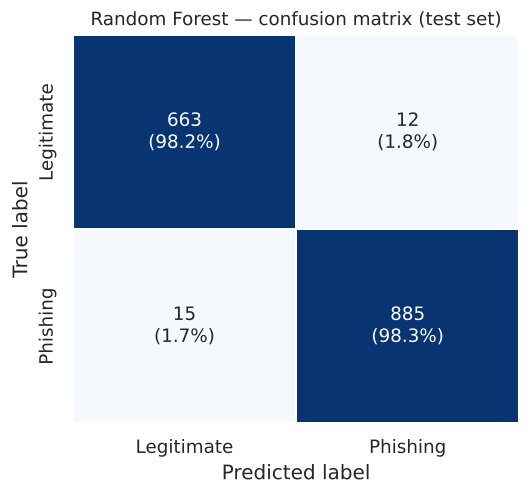

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
labels = ["Legitimate", "Phishing"]
annot = np.array([[f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"False positive rate = {fp / (fp + tn):.4f} | False negative rate = {fn / (fn + tp):.4f}")

fig, ax = plt.subplots(figsize=(4.8, 4.2))
sns.heatmap(cm_pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False,
            xticklabels=labels, yticklabels=labels, linewidths=1, linecolor="white",
            annot_kws={"size": 11}, ax=ax)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Random Forest — confusion matrix (test set)", fontsize=11)
plt.savefig("fig_confusion_matrix.png")
plt.show()

## 10. Feature importance

Two measures are computed:

- **MDI (impurity-based)** — `feature_importances_`, the total Gini decrease attributable to each feature, averaged over trees. Computed on training data; inflated for continuous features with many distinct split points (e.g. `urlentropy`, `percentagenumericchars`) and for features correlated with each other.
- **Permutation importance** — drop in test-set ROC-AUC when one feature's values are shuffled (30 repeats). Measured on unseen data and directly tied to predictive performance. Error bars show ± 1 SD across repeats.

When the two rankings disagree, the permutation ranking is the one to report. Correlated features (e.g. `urllength`, `pathlength`, `count_non_alphanumeric`) share importance under permutation: shuffling one leaves the information available through the others, so each can look less important than the group is; unrestricted permutation also forces the model to extrapolate to unrealistic feature combinations [4].

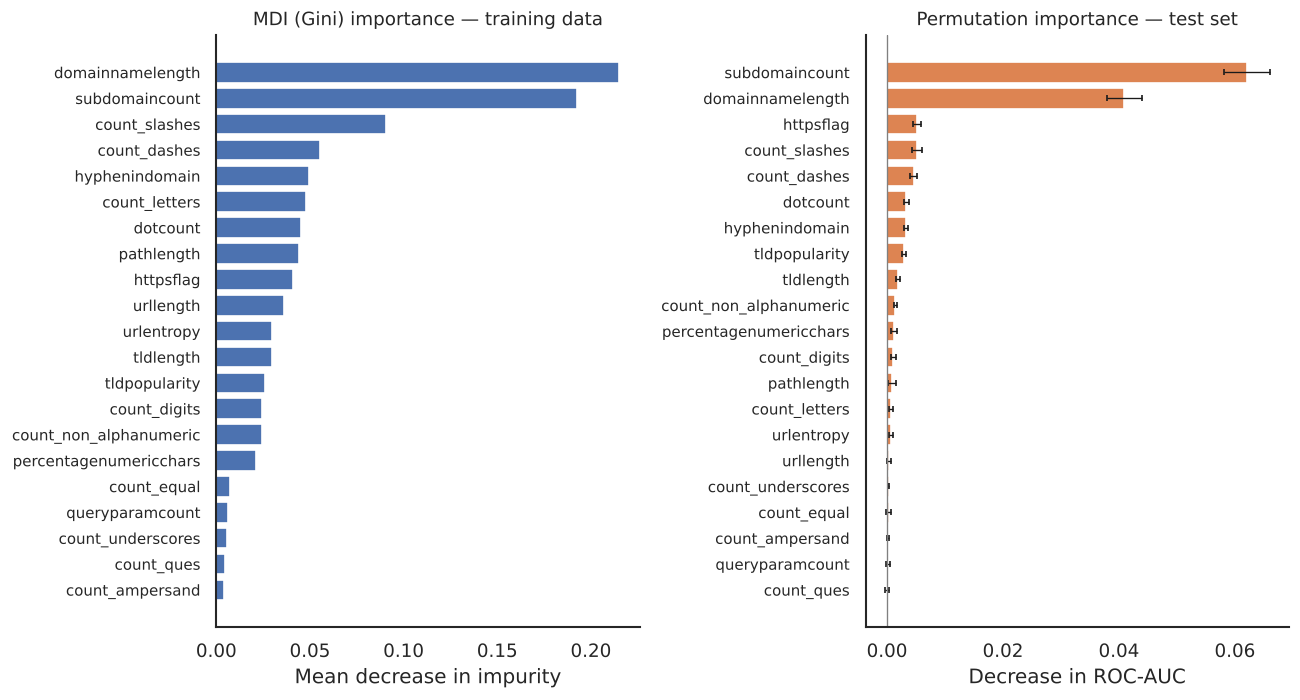

,MDI,perm_mean,perm_sd,MDI_rank,perm_rank
subdomaincount,0.1927,0.0620,0.0039,2,1
domainnamelength,0.2152,0.0409,0.0030,1,2
httpsflag,0.0410,0.0052,0.0007,9,3
count_slashes,0.0904,0.0051,0.0009,3,4
count_dashes,0.0555,0.0046,0.0006,4,5
dotcount,0.0451,0.0034,0.0004,7,6
hyphenindomain,0.0495,0.0033,0.0004,5,7
tldpopularity,0.0258,0.0029,0.0003,13,8
tldlength,0.0295,0.0019,0.0004,12,9
count_non_alphanumeric,0.0243,0.0014,0.0002,15,10


In [10]:
mdi = pd.Series(rf.feature_importances_, index=features, name="MDI")

perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=SEED, n_jobs=-1)
perm_df = pd.DataFrame({"perm_mean": perm.importances_mean, "perm_sd": perm.importances_std},
                       index=features)

importance = pd.concat([mdi, perm_df], axis=1)
importance["MDI_rank"] = importance["MDI"].rank(ascending=False).astype(int)
importance["perm_rank"] = importance["perm_mean"].rank(ascending=False).astype(int)
importance = importance.sort_values("perm_mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=False)

mdi_sorted = importance["MDI"].sort_values()
axes[0].barh(mdi_sorted.index, mdi_sorted.values, color="#4C72B0")
axes[0].set_title("MDI (Gini) importance — training data", fontsize=11)
axes[0].set_xlabel("Mean decrease in impurity")

perm_sorted = importance.sort_values("perm_mean")
axes[1].barh(perm_sorted.index, perm_sorted["perm_mean"], xerr=perm_sorted["perm_sd"],
             color="#DD8452", error_kw={"elinewidth": 0.8, "capsize": 2})
axes[1].axvline(0, color="grey", lw=0.8)
axes[1].set_title("Permutation importance — test set", fontsize=11)
axes[1].set_xlabel("Decrease in ROC-AUC")

for ax in axes:
    ax.tick_params(axis="y", labelsize=9)
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("fig_feature_importance.png")
plt.show()

importance.round(4)

### Direction of effect

Importance says *how much* a feature matters, not *which way*. The class-conditional medians below give the direction (e.g. phishing URLs are longer). For a model-based view of direction, use SHAP or partial-dependence plots.

In [11]:
top = importance.index[:8]
direction = (train_model.groupby(TARGET)[list(top)].median().T
             .rename(columns={0: "median_legit", 1: "median_phish"}))
direction["mean_legit"] = train_model.loc[y_train == 0, top].mean()
direction["mean_phish"] = train_model.loc[y_train == 1, top].mean()
direction.round(3)

ClassLabel,median_legit,median_phish,mean_legit,mean_phish
subdomaincount,1.0,0.0,0.911,0.522
domainnamelength,15.0,19.0,15.667,21.263
httpsflag,1.0,1.0,0.955,0.722
count_slashes,4.0,5.0,4.055,5.571
count_dashes,1.0,1.0,2.418,1.589
dotcount,2.0,2.0,2.327,3.044
hyphenindomain,0.0,0.0,0.000,0.206
tldpopularity,1.0,1.0,0.836,0.593


## 11. Interpreting the results

*Figures quoted below are from a reference run (scikit-learn 1.9, `SEED = 42`, default configuration). Small differences across library versions are expected.*

### 11.1 Read the test score together with the grouped CV score

| Evaluation | Accuracy | F1 (phishing) | MCC |
|---|---|---|---|
| Grouped 5-fold CV on train (host-disjoint folds) | 0.878 ± 0.043 | 0.902 ± 0.032 | 0.759 ± 0.083 |
| Provided test split | 0.983 [0.976, 0.989] | 0.985 [0.979, 0.991] | 0.965 [0.951, 0.978] |

The gap is about 10 accuracy points and about 0.21 MCC. The audit in section 3 explains it: the legitimate class covers only 63 hosts, and **99.1% of legitimate test URLs come from hosts already in the training set**. On the provided split, the model is largely asked to recognise sites it has already seen; the grouped CV asks it to generalise to unseen sites.

For a paper: report both numbers, name the provided split's test score as an in-distribution result, and treat the grouped estimate as the better estimate of performance on new domains. Reporting only the 98% figure would overstate generalisation.

### 11.2 Reading the importance plots

- **Height of a bar** = how much the model relies on that feature, not whether the feature is causally linked to phishing.
- **MDI vs permutation:** both rankings put `subdomaincount` and `domainnamelength` far ahead of everything else. Further down they diverge. The length and count features drop under permutation: `count_letters` (MDI rank 6 → permutation 14), `pathlength` (8 → 13), `urlentropy` (11 → 15), `urllength` (10 → 16). This is expected for continuous features that MDI inflates and that duplicate one another. Binary features rise: `httpsflag` (9 → 3) and `tldpopularity` (13 → 8), because they cannot gain from many split points under MDI. Use the permutation ranking for claims.
- **Redundant groups:** section 3 lists feature pairs with |Spearman ρ| ≥ 0.9: `urllength`–`count_letters`, `percentagenumericchars`–`count_digits`, and the query-string group `queryparamcount`–`count_ques`–`count_equal`. When one member is permuted the model reads the same information from its partner, so each member looks weak even if the group matters. This is why the whole query-string group sits at the bottom with near-zero permutation importance. To quantify a group, permute its members jointly or keep one feature per correlated cluster.
- **Removed features:** `hash`, `hasipaddress` and `suspiciousfileextension` are constant in the training set and were dropped in section 4. They are absent from the results because this corpus contains no IP-based or file-extension examples in training, not because those cues are unimportant in general.

### 11.3 What the top features actually capture

The two dominant features describe the **host**, not the path:

- `subdomaincount` — legitimate rows have a median of 1, phishing rows 0. The extractor counts `www.` as a subdomain, and legitimate job portals almost always use `www.` or a country prefix. Phishing URLs here are mostly bare compromised domains (`*.co.in/css/.../linkedin.html`). The feature is therefore largely detecting the presence of `www.`.
- `domainnamelength` — phishing domains are longer (median 19 vs 15 characters), which fits long deceptive hostnames. With only 63 legitimate hosts, however, a tree can also isolate those hosts by their exact domain-name length, which acts as a host identifier.
- `hyphenindomain` is 0 for **every** legitimate training row. It is a perfect one-way rule in this sample, but a property of the chosen portals, not of legitimate sites in general.

Implication for the discussion section: the model's discriminative power comes mainly from the contrast between a narrow set of well-known job portals and a diverse set of phishing hosts. That is legitimate signal for this deployment scenario (screening links that claim to be job postings), but it should be stated explicitly, and the legitimate class should be broadened (more portals and company career pages) before claiming generalisation.

### References

[1] S. Nembrini, I. R. König, and M. N. Wright, "The revival of the Gini importance?," *Bioinformatics*, vol. 34, no. 21, pp. 3711–3718, 2018, doi: 10.1093/bioinformatics/bty373.

[2] L. Breiman, "Random forests," *Mach. Learn.*, vol. 45, no. 1, pp. 5–32, 2001, doi: 10.1023/A:1010933404324.

[3] D. Chicco and G. Jurman, "The advantages of the Matthews correlation coefficient (MCC) over F1 score and accuracy in binary classification evaluation," *BMC Genomics*, vol. 21, art. no. 6, 2020, doi: 10.1186/s12864-019-6413-7.

[4] G. Hooker, L. Mentch, and S. Zhou, "Unrestricted permutation forces extrapolation: Variable importance requires at least one more model, or there is no free variable importance," *Stat. Comput.*, vol. 31, no. 6, art. no. 82, 2021.